In [1]:
# Cài đặt nltk (nếu chưa có) và tải dữ liệu cần thiết
!pip install -q nltk

import nltk

# Tải stopwords, wordnet, pos_tagger và bộ dữ liệu mẫu từ NLTK Book
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_eng')
nltk.download('words')
nltk.download('book')

print("-> Đã tải xong tài nguyên NLTK!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Error loading maxent_ne_chunker_eng: Package
[nltk_data]   

-> Đã tải xong tài nguyên NLTK!


[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | 
[nltk_data]  Done downloading collection book


In [2]:
import re
import string
from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

raw_text = """
Natural Language Toolkit (NLTK) is very useful for NLP!
Check out https://www.nltk.org/ for more details 😊.
Students are studying text preprocessing and building models every day.
"""

# 1. Làm sạch URL, emoji cơ bản và chuyển chữ thường
cleaned_text = re.sub(r'http\S+', '', raw_text).lower()
cleaned_text = re.sub(r'[^\x00-\x7F]+', ' ', cleaned_text) # loại bỏ ký tự ngoài ASCII (như emoji)

# 2. Tách câu và tách từ
sentences = sent_tokenize(cleaned_text)
print("Các câu sau khi tách:", sentences)

# 3. Loại bỏ dấu câu và stop words tiếng Anh
stop_words = set(stopwords.words('english'))
punct_table = str.maketrans('', '', string.punctuation)

filtered_tokens = []
for s in sentences:
    s_no_punct = s.translate(punct_table)
    words = word_tokenize(s_no_punct)
    words_clean = [w for w in words if w not in stop_words and w.isalpha()]
    filtered_tokens.extend(words_clean)

print("Tokens sau khi bỏ dấu câu & stop words:", filtered_tokens)

# 4. Đếm tần suất từ bằng Counter (giúp nhận diện từ hiếm gặp)
word_counts = Counter(filtered_tokens)
print("Tần suất từ:", word_counts)

Các câu sau khi tách: ['\nnatural language toolkit (nltk) is very useful for nlp!', 'check out  for more details  .', 'students are studying text preprocessing and building models every day.']
Tokens sau khi bỏ dấu câu & stop words: ['natural', 'language', 'toolkit', 'nltk', 'useful', 'nlp', 'check', 'details', 'students', 'studying', 'text', 'preprocessing', 'building', 'models', 'every', 'day']
Tần suất từ: Counter({'natural': 1, 'language': 1, 'toolkit': 1, 'nltk': 1, 'useful': 1, 'nlp': 1, 'check': 1, 'details': 1, 'students': 1, 'studying': 1, 'text': 1, 'preprocessing': 1, 'building': 1, 'models': 1, 'every': 1, 'day': 1})


In [3]:
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

sample_words = ["studies", "studying", "connected", "connection", "better", "cars"]

print("Stemming (PorterStemmer):")
print([stemmer.stem(w) for w in sample_words])

pos_tags = nltk.pos_tag(sample_words)
print("Lemmatization (WordNetLemmatizer + POS):")
print([(w, lemmatizer.lemmatize(w, get_wordnet_pos(tag))) for w, tag in pos_tags])

Stemming (PorterStemmer):
['studi', 'studi', 'connect', 'connect', 'better', 'car']
Lemmatization (WordNetLemmatizer + POS):
[('studies', 'study'), ('studying', 'study'), ('connected', 'connect'), ('connection', 'connection'), ('better', 'well'), ('cars', 'car')]


In [5]:
import nltk
from nltk.book import text1, text3, text4, text5

# 1. Tìm ngữ cảnh từ khóa (concordance) và từ tương tự ngữ cảnh (similar)
print("=== Concordance của 'monstrous' trong text1 ===")
text1.concordance("monstrous")

print("\n=== Từ có ngữ cảnh tương tự 'monstrous' trong text1 ===")
text1.similar("monstrous")

# 2. Thông tin ngữ liệu, kích thước từ vựng và độ đa dạng từ vựng (lexical diversity)
def lexical_diversity(text):
    return len(set(text)) / len(text)

print("\n=== Thống kê ngữ liệu ===")
print("Tên ngữ liệu:", text3)
print("Tổng số token:", len(text3))
print("Số từ vựng duy nhất:", len(set(text3)))
print(f"Lexical diversity của text3: {lexical_diversity(text3):.4f}")
print(f"Lexical diversity của text5: {lexical_diversity(text5):.4f}")

=== Concordance của 'monstrous' trong text1 ===
Displaying 11 of 11 matches:
ong the former , one was of a most monstrous size . ... This came towards us , 
ON OF THE PSALMS . " Touching that monstrous bulk of the whale or ork we have r
ll over with a heathenish array of monstrous clubs and spears . Some were thick
d as you gazed , and wondered what monstrous cannibal and savage could ever hav
that has survived the flood ; most monstrous and most mountainous ! That Himmal
they might scout at Moby Dick as a monstrous fable , or still worse and more de
th of Radney .'" CHAPTER 55 Of the Monstrous Pictures of Whales . I shall ere l
ing Scenes . In connexion with the monstrous pictures of whales , I am strongly
ere to enter upon those still more monstrous stories of them which are to be fo
ght have been rummaged out of this monstrous cabinet there is no telling . But 
of Whale - Bones ; for Whales of a monstrous size are oftentimes cast up dead u

=== Từ có ngữ cảnh tương tự 'monstrous' tr

<Figure size 1000x400 with 0 Axes>

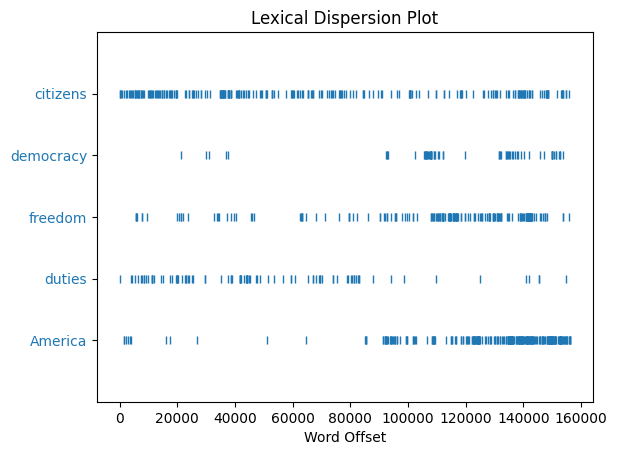

In [6]:
import matplotlib.pyplot as plt
from nltk.book import text4

plt.figure(figsize=(10, 4))
text4.dispersion_plot(["citizens", "democracy", "freedom", "duties", "America"])
plt.show()